# WIND Contract Factor Forecast
Portfolio-level (WIND aggregate) forecast of the monthly Contract Factor (CF). Test set: FY2026 (models trained on FY23–25).

- **Wind speed** uses the **QM-corrected** series (`dtn_weather_89002_86338_qm.csv`) for stations 89002/86338. The QM override applies **only to `wind_speed_kph`**; `temp_c`, `rh` and wind direction use the original (non-QM) data.
- **Price features**: TWAP is split into **`twap_neg`** (mean of the negative half-hours) and **`twap_pos`** (mean of the non-negative half-hours). The plain monthly `twap` is only used by the Exponential baseline and as the target of the scenarios.
- **Generation**: NEMSight data with exclusion periods left as NaN (no backfill).
- **Weather driver**: `wind_speed_kph` is the mean of stations 86338 and 89002.

## Set up

In [29]:
# =============================================================================
# CELL: Imports and configuration
# Imports libraries and project functions (utilsData, utilsModels, utilsScenario),
# sets the data folder, and defines the
# `cfg` dict (analysis window, train/test FYs, assets, weather stations, model params).
# =============================================================================

# pip install numpy pandas matplotlib seaborn plotly scipy scikit-learn statsmodels xgboost lightgbm pytz ipykernel

import os
import sys
import warnings
import datetime as dt
from typing import Dict, Tuple

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from statsmodels.stats.outliers_influence import variance_inflation_factor

warnings.filterwarnings("ignore")

# Project functions live in ../functions (notebook runs from notebooks/)
sys.path.append(os.path.abspath('../functions'))

# Data, model and scenario helpers (the other .py files are imported by these)
from utilsContractFactors import getFY
from utilsData import (_to_naive_timestamp, _reindex_and_interpolate, month_end_labels,
                       load_generation_inputs, build_targets, load_weather_history)
from utilsModels import run_all_models, predict_method
from utilsScenario import (shrink_factor, load_forward_twap_monthly, build_scenario_table,
                           predict_scenarios, monthly_depth, summarise)

DATA_DIR = '../data'  # folder with all input CSVs

cfg = {
    'random_seed': 42,
    'zero_dollar_floor': True,                    # floor prices at $0 when computing contract revenue

    # Train/test split by financial year (FY ends in June)
    'train_fys': [2023, 2024, 2025],
    'test_fys': [2026],
    'analysis_start': '2022-07-01 00:00:00',
    'analysis_end': '2026-06-30 23:30:00',

    # Assets and weather stations
    'wind_assets': ['DUNDWF3', 'BRYB1WF1', 'BULGANA1', 'MRTLSWF1'],
    'solar_assets': ['WINTSF1', 'GLENSF1', 'COHUNSF1'],
    'station_ids': [85280, 86338, 89002],
    'driver_stations': [86338, 89002],            # stations averaged into the monthly wind features
    'weather_interp_limit': 2,                    # max consecutive 30-min gaps to interpolate
    'corruption_range': ('2025-10-07', '2026-04-14'),  # period with corrupted wind speed data

    # Model settings
    'sarimax_order': (1, 0, 0),
    'rf_params': {
        'n_estimators': 300,
        'max_depth': 4,
        'min_samples_leaf': 2,
        'random_state': 42,
    },
    'xgb_params': {
        'n_estimators': 250,
        'max_depth': 3,
        'learning_rate': 0.05,
        'subsample': 0.9,
        'colsample_bytree': 0.9,
        'reg_lambda': 1.0,
        'random_state': 42,
    },
    'lgbm_params': {
        'n_estimators': 200,
        'max_depth': 3,
        'learning_rate': 0.05,
        'min_child_samples': 3,
        'random_state': 42,
        'verbose': -1,
    },
    'alpha_grid': np.logspace(0, 2, 15),          # candidate alphas for RidgeCV
}

ALL_ASSETS = cfg['wind_assets'] + cfg['solar_assets']
np.random.seed(cfg['random_seed'])

## Load data

In [30]:
# =============================================================================
# CELL: Load weather history 
# Reads DTN wind/temperature and Solcast solar data from data/ for the chosen stations,
# overrides wind_speed_kph at stations 89002/86338 with the quantile-mapped (QM) series,
# and builds `weather_hh` (half-hourly, wide: one column per metric and station)
# plus `weather_raw` (long-format wind data).
# =============================================================================

weather_hh, weather_raw = load_weather_history(cfg)
print('Weather history rows:', len(weather_hh))

QM file loaded: 70,098 rows, cols: ['temp_c_89002', 'rh_89002', 'wind_speed_kph_89002', 'wind_dir_degrees_89002', 'temp_c_86338', 'rh_86338', 'wind_speed_kph_86338', 'wind_dir_degrees_86338', 'qm_corrected']
QM overlay applied to wind_speed_kph only: 70,098 HH matched, 9,102 HH were QM-corrected
Weather history rows: 70128


In [31]:
# =============================================================================
# CELL: Load generation inputs 
# Reads NEMSight generation, VRET asset data, exclusion periods and MLF from data/,
# applies exclusions (set to NaN), MLF and contracted-capacity scaling, and builds
# the half-hourly generation table `gen_scaled` (ALL_ASSETS + VIC1Price)
# plus asset capacities (MW). Exclusion periods are left as NaN.
# =============================================================================

gen_scaled, vret_data, capacity = load_generation_inputs(cfg, DATA_DIR)

print(f'Generation: {gen_scaled.shape[0]:,} rows x {gen_scaled.shape[1]} cols')
print(f'Period: {gen_scaled.index.min()} -> {gen_scaled.index.max()}')
print('\nMissing share per asset (%):')
print((gen_scaled[ALL_ASSETS].isna().mean() * 100).round(1).to_string())
print('\nCapacity (MW):', {k: round(v, 1) for k, v in capacity.items()})

...extending exclusions
...exclusion period 1 updated to COHUNSF1 2021-10-01 00:00:00 to 2022-03-31 00:00:00
...exclusion period 11 updated to COHUNSF1 2023-10-01 00:00:00 to 2023-10-31 00:00:00
...exclusion period 12 updated to COHUNSF1 2023-12-01 00:00:00 to 2023-12-31 00:00:00
...exclusion period 18 updated to COHUNSF1 2024-03-30 00:00:00 to 2025-04-30 00:00:00
...exclusion period 39 updated to COHUNSF1 2026-01-01 00:00:00 to 2026-01-31 00:00:00
...exclusion period 42 updated to COHUNSF1 2026-04-01 00:00:00 to 2026-06-30 00:00:00
...exclusion period 43 updated to WINTSF1 2024-07-01 00:00:00 to 2024-08-31 00:00:00
...exclusion period 44 updated to WINTSF1 2024-11-01 00:00:00 to 2025-01-07 00:00:00
...exclusion period 52 updated to BULGANA1 2024-06-01 00:00:00 to 2025-12-31 00:00:00
...exclusion period 53 updated to BULGANA1 2026-01-01 00:00:00 to 2026-02-03 00:00:00
...exclusion period 61 updated to BRYB1WF1 2022-02-01 00:00:00 to 2022-02-28 00:00:00
...exclusion period 64 updated to

In [32]:
# =============================================================================
# CELL: Load price forecast and LGC prices
# Reads the half-hourly VIC forward price curve (Central scenario) and the monthly
# LGC/STC/VEEC certificate prices from data/.
# =============================================================================

# 1. Half-hourly VIC price forecast (Central scenario)
price_forecast = pd.read_csv(
    os.path.join(DATA_DIR, 'VIC_Central_30min_PriceForecast.csv'),
    parse_dates=['Time-ending'],
    dayfirst=True,  # dates are dd/mm/yyyy
)
price_forecast = price_forecast.set_index('Time-ending').sort_index()
print(f'Price forecast: {len(price_forecast):,} rows, {price_forecast.index.min()} to {price_forecast.index.max()}')
display(price_forecast.head())

# 2. Monthly LGC / STC / VEEC certificate prices
lgc_prices = pd.read_csv(
    os.path.join(DATA_DIR, '20260424_HistoricLGCPrice.csv'),
    index_col=0,
    parse_dates=True,
    dayfirst=True,
    encoding='utf-8-sig',  # strips the BOM that Excel adds to CSV files
)
lgc_prices.index.name = 'Date'
print(f'\nLGC prices: {len(lgc_prices)} rows, {lgc_prices.index.min().strftime("%Y-%m")} to {lgc_prices.index.max().strftime("%Y-%m")}')
display(lgc_prices.tail(10))

Price forecast: 613,632 rows, 2025-07-01 00:30:00 to 2060-07-01 00:00:00


,Price
Time-ending,
2025-07-01 00:30:00,120.3
2025-07-01 01:00:00,118.6
2025-07-01 01:30:00,124.7
2025-07-01 02:00:00,128.4
2025-07-01 02:30:00,120.7



LGC prices: 69 rows, 2021-01 to 2026-09


,LGC,STC,VEEC
Date,,,
2025-12-31,6.74,39.80,79.74
2026-01-31,6.49,39.57,78.47
2026-02-28,4.27,39.60,81.38
2026-03-31,3.20,39.63,82.96
2026-04-30,2.52,NaN,NaN
2026-05-31,2.28,NaN,NaN
2026-06-30,5.83,NaN,NaN
2026-07-31,5.94,NaN,NaN
2026-08-31,7.91,NaN,NaN


In [33]:
# =============================================================================
# CELL: Build monthly targets
# Converts the half-hourly generation into `monthly_target`: monthly contract
# factors per asset and for the WIND fleet, plus calendar features
# (month sin/cos, FY, Season). Also keeps the half-hourly price as `price_hh`
# for the price diagnostics and the LGC cells.
# =============================================================================
monthly_target = build_targets(gen_scaled, cfg, capacity)
price_hh = gen_scaled['VIC1Price']   # half-hourly VIC1 price ($/MWh)

# Quick check: row count and the first months of the main target
print(f'{len(monthly_target)} monthly rows')
display(monthly_target[['WIND_ContractFactor', 'VIC1Price_TWAP']].reset_index().head(5))

48 monthly rows


,Time-ending,WIND_ContractFactor,VIC1Price_TWAP
0,2022-07-31,0.784076,340.076956
1,2022-08-31,0.668533,122.152144
2,2022-09-30,0.834403,111.759882
3,2022-10-31,0.782442,98.813427
4,2022-11-30,0.851770,58.687569


In [34]:
# =============================================================================
# CELL: Monthly driver weather features
# Weather-only features (independent of the generation data), averaged over the
# stations in cfg['driver_stations']: wind_speed_kph, temp_mean, rh_mean and
# wind direction as sin/cos. Direction is averaged as sin/cos across stations
# BEFORE the monthly mean, so it wraps around 0/360 degrees correctly.
# Output: `weather_monthly_wind` (month-end index).
# =============================================================================
driver_stations = cfg['driver_stations']   # [86338, 89002]


def _station_cols(metric: str) -> list:
    """Columns of weather_hh for one metric, restricted to the driver stations."""
    return [f'{metric}_{s}' for s in driver_stations if f'{metric}_{s}' in weather_hh.columns]


month_labels = month_end_labels(weather_hh.index)   # month-end label of every half-hour

# Average across stations first, then across the half-hours of each month
weather_monthly_wind = pd.DataFrame({
    'wind_speed_kph': weather_hh[_station_cols('wind_speed_kph')].mean(axis=1).groupby(month_labels).mean(),
    'temp_mean': weather_hh[_station_cols('temp_c')].mean(axis=1).groupby(month_labels).mean(),
    'rh_mean': weather_hh[_station_cols('rh')].mean(axis=1).groupby(month_labels).mean(),
    'sin_wind_dir_raw': weather_hh[_station_cols('sin_wind_dir')].mean(axis=1).groupby(month_labels).mean(),
    'cos_wind_dir_raw': weather_hh[_station_cols('cos_wind_dir')].mean(axis=1).groupby(month_labels).mean(),
})
weather_monthly_wind.index.name = 'Time-ending'

print('weather_monthly_wind (driver features):', weather_monthly_wind.shape)
display(weather_monthly_wind.describe().round(3))

weather_monthly_wind (driver features): (48, 5)


,wind_speed_kph,temp_mean,rh_mean,sin_wind_dir_raw,cos_wind_dir_raw
count,48.000,48.000,48.000,48.000,48.000
mean,14.353,14.156,72.108,-0.069,-0.065
std,1.661,3.919,7.414,0.135,0.332
min,8.247,8.232,59.119,-0.411,-0.607
25%,13.931,10.928,66.790,-0.146,-0.330
50%,14.725,13.543,71.113,-0.052,-0.112
75%,15.278,17.575,79.246,0.031,0.163
max,16.659,20.559,86.436,0.180,0.670


In [35]:
# =============================================================================
# CELL: Build the monthly feature table `df_wind`
# One row per month with: target CF, price features (twap_neg, twap_pos), plain
# twap (only for the Exponential baseline and the scenario target), month_sin/cos,
# FY, Season, driver weather features (wind_speed_kph, rh, temp_c, wind direction
# sin/cos) and CF_lag12 (for Seasonal Naive).
# =============================================================================
def build_twap_split_monthly(price: pd.Series) -> pd.DataFrame:
    """Monthly mean of the negative and of the non-negative half-hourly prices.

    twap_neg: mean of half-hours with price < 0 (NaN if a month has none).
    twap_pos: mean of half-hours with price >= 0 (zero prices count as positive).

    Args:
        price: Half-hourly VIC1 price with a DatetimeIndex.

    Returns:
        DataFrame with columns twap_neg and twap_pos on a month-end index.
    """
    labels = month_end_labels(price.index)
    neg = price.where(price < 0).groupby(labels).mean()
    pos = price.where(price >= 0).groupby(labels).mean()
    out = pd.DataFrame({'twap_neg': neg, 'twap_pos': pos})
    out.index.name = 'Time-ending'
    return out


twap_split_monthly = build_twap_split_monthly(price_hh)

df_wind = pd.DataFrame(index=monthly_target.index)
df_wind['target'] = monthly_target['WIND_ContractFactor']
df_wind['twap'] = monthly_target['VIC1Price_TWAP']
df_wind['twap_neg'] = twap_split_monthly['twap_neg'].reindex(df_wind.index)
df_wind['twap_pos'] = twap_split_monthly['twap_pos'].reindex(df_wind.index)
df_wind['month_sin'] = monthly_target['month_sin']
df_wind['month_cos'] = monthly_target['month_cos']
df_wind['FY'] = monthly_target['FY']
df_wind['Season'] = monthly_target['Season']

# Driver weather features (same for every model)
df_wind['wind_speed_kph'] = weather_monthly_wind['wind_speed_kph'].reindex(df_wind.index)
df_wind['rh'] = weather_monthly_wind['rh_mean'].reindex(df_wind.index)
df_wind['temp_c'] = weather_monthly_wind['temp_mean'].reindex(df_wind.index)
df_wind['sin_wind_dir_raw'] = weather_monthly_wind['sin_wind_dir_raw'].reindex(df_wind.index)
df_wind['cos_wind_dir_raw'] = weather_monthly_wind['cos_wind_dir_raw'].reindex(df_wind.index)

# Same month one year earlier (Seasonal Naive forecast)
df_wind['CF_lag12'] = df_wind['target'].shift(12)

# Train/test split and the period with corrupted wind data (used in plots)
TRAIN_FYS = cfg['train_fys']
TEST_FYS = cfg['test_fys']
CORR_START = pd.Timestamp(cfg['corruption_range'][0])
CORR_END = pd.Timestamp(cfg['corruption_range'][1])

n_missing_split = int(df_wind[['twap_neg', 'twap_pos']].isna().any(axis=1).sum())
print(f'{len(df_wind)} rows, train={df_wind["FY"].isin(TRAIN_FYS).sum()}, test={df_wind["FY"].isin(TEST_FYS).sum()}')
print(f'Months with no negative or no positive half-hours (NaN twap_neg/twap_pos): {n_missing_split}')
display(df_wind[['twap', 'twap_neg', 'twap_pos']].describe().round(2))
display(df_wind.tail(3))

48 rows, train=36, test=12
Months with no negative or no positive half-hours (NaN twap_neg/twap_pos): 0


,twap,twap_neg,twap_pos
count,48.00,48.00,48.00
mean,75.80,-29.30,103.41
std,60.20,13.79,58.96
min,17.25,-53.18,45.60
25%,43.17,-40.99,69.68
50%,60.18,-29.60,88.99
75%,83.97,-17.71,108.98
max,340.08,-1.92,375.36


,target,twap,twap_neg,twap_pos,month_sin,month_cos,FY,Season,wind_speed_kph,rh,temp_c,sin_wind_dir_raw,cos_wind_dir_raw,CF_lag12
Time-ending,,,,,,,,,,,,,,
2026-04-30,0.472227,35.686907,-8.863473,57.205062,8.660254e-01,-0.500000,2026,2,8.247260,69.663008,15.057586,-0.083000,0.205451,0.717903
2026-05-31,0.485221,64.796970,-1.924007,76.620940,5.000000e-01,-0.866025,2026,2,11.735037,81.100302,13.000386,-0.059533,0.286904,0.428533
2026-06-30,0.504665,66.786087,-2.499299,79.347261,1.224647e-16,-1.000000,2026,3,14.380687,86.435764,10.989253,0.019399,0.574380,0.315887


## Check positive & negative TWAP

Half-hourly intervals: 70128
Negative-price intervals: 16079 (22.93% of all half-hours)

Price distribution when negative ($/MWh):


,stat,price
0,count,16079.00
1,mean,-31.44
2,std,32.82
3,min,-521.89
4,25%,-46.45
5,50%,-25.84
6,75%,-9.44
7,max,-0.00



Negative-price half-hour count and mean price by FY:


,FY,count,mean,min
0,2023,3497,-36.35,-521.89
1,2024,3751,-44.20,-423.70
2,2025,4203,-34.73,-463.45
3,2026,4628,-14.40,-249.46


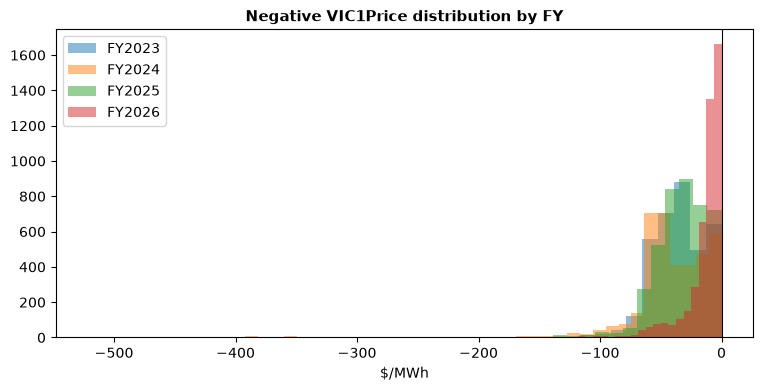


Negative-price half-hour COUNT by FY and $/MWh range:


price_bin,FY,-10 to 0,-50 to -10,-100 to -50,below -100
0,2023,517,2096,846,38
1,2024,553,1780,1247,171
2,2025,651,2790,668,94
3,2026,2516,1846,229,37



Negative-price half-hour SHARE (of total half-hours in that FY) by $/MWh range:


price_bin,FY,-10 to 0,-50 to -10,-100 to -50,below -100
0,2023,2.951%,11.963%,4.829%,0.217%
1,2024,3.148%,10.132%,7.098%,0.973%
2,2025,3.716%,15.925%,3.813%,0.537%
3,2026,14.361%,10.537%,1.307%,0.211%


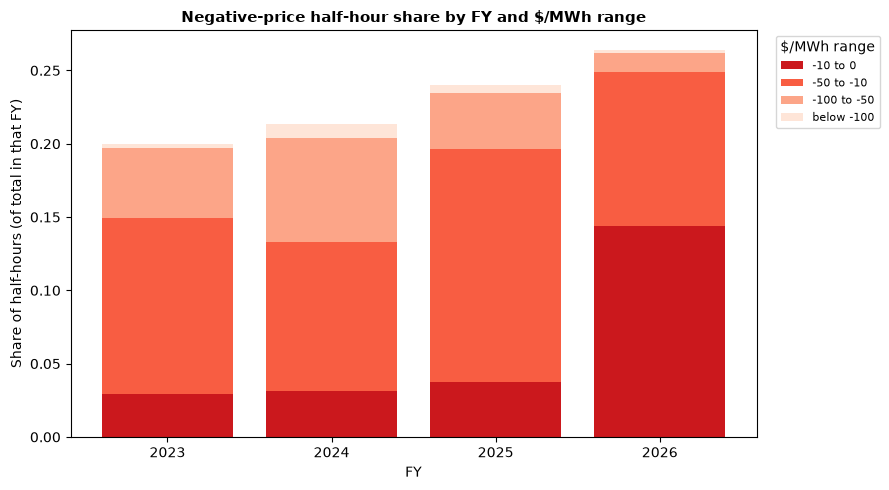


Months with ZERO negative-price half-hours: 0 / 48


,stat,VIC1Price
0,count,48.0000
1,mean,0.2293
2,std,0.1036
3,min,0.0368
4,25%,0.1530
5,50%,0.2349
6,75%,0.2969
7,max,0.4507


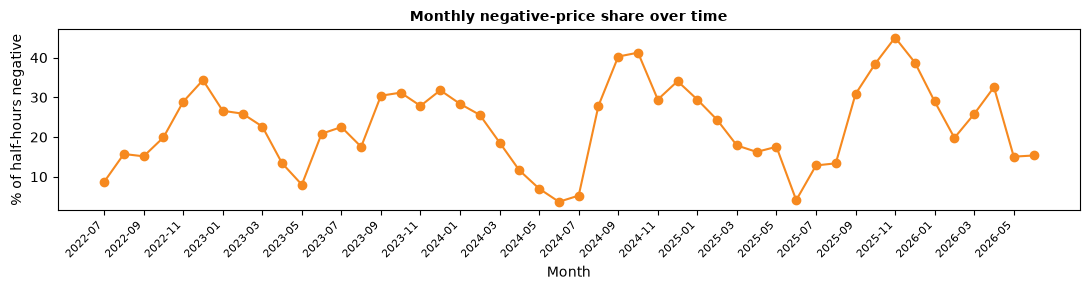

In [36]:
# =============================================================================
# CELL: Negative-price diagnostic
# Checks BEFORE trusting a negative-price feature: how often VIC1Price is negative,
# how deep it goes, how it differs by FY and by month, and how sparse twap_neg is
# at monthly grain (months with no negative half-hour).
# =============================================================================
_price_hh = price_hh   # half-hourly VIC1 price (from the targets cell)
_fy_hh = getFY(_price_hh.index)
_df_price = pd.DataFrame({'price': _price_hh, 'FY': _fy_hh})
_df_neg = _df_price[_df_price['price'] < 0].copy()
_neg_mask_hh = _price_hh < 0

print(f'Half-hourly intervals: {len(_price_hh)}')
print(f'Negative-price intervals: {_neg_mask_hh.sum()} ({_neg_mask_hh.mean()*100:.2f}% of all half-hours)')
print()
print('Price distribution when negative ($/MWh):')
display(_df_neg['price'].describe().round(2).reset_index().rename(columns={'index': 'stat'}))

# --- Histogram of negative prices, one overlay per FY ---
fys = sorted(_df_neg['FY'].unique())
print()
print('Negative-price half-hour count and mean price by FY:')
display(_df_neg.groupby('FY')['price'].agg(count='size', mean='mean', min='min').round(2).reset_index())

fig, ax = plt.subplots(figsize=(9, 4))
for fy in fys:
    ax.hist(_df_neg.loc[_df_neg['FY'] == fy, 'price'], bins=40, alpha=0.5, label=f'FY{fy}')
ax.axvline(0, color='black', linewidth=0.8)
ax.set_title('Negative VIC1Price distribution by FY', fontsize=11, fontweight='bold')
ax.set_xlabel('$/MWh')
ax.legend()
display(fig)
plt.close(fig)

# --- Depth bins: 0 to -10, -10 to -50, -50 to -100, below -100 ---
# Share = fraction of ALL half-hours in that FY, so each stacked bar sums to the FY's negative share.
_min_price = _df_neg['price'].min()
_lowest_edge = min(int(np.floor(_min_price / 10) * 10), -101)   # must lie below the -100 edge
_bin_edges = [_lowest_edge, -100, -50, -10, 0]
_bin_labels = ['below -100', '-100 to -50', '-50 to -10', '-10 to 0']

_df_neg['price_bin'] = pd.cut(_df_neg['price'], bins=_bin_edges, labels=_bin_labels, right=True, ordered=True)

_total_by_fy = _fy_hh.value_counts()
_bin_counts = _df_neg.groupby(['FY', 'price_bin'], observed=False).size().unstack(fill_value=0)
_bin_ratio = _bin_counts.div(_total_by_fy, axis=0)
_bin_ratio = _bin_ratio[_bin_ratio.columns[::-1]]  # closest-to-zero first

print()
print('Negative-price half-hour COUNT by FY and $/MWh range:')
display(_bin_counts[_bin_counts.columns[::-1]].reset_index())
print()
print('Negative-price half-hour SHARE (of total half-hours in that FY) by $/MWh range:')
display(((_bin_ratio * 100).round(3).astype(str) + '%').reset_index())

fig2, ax2 = plt.subplots(figsize=(9, 5))
bottom = np.zeros(len(_bin_ratio))
colors = plt.cm.Reds_r(np.linspace(0.25, 0.9, len(_bin_ratio.columns)))
for i, col in enumerate(_bin_ratio.columns):
    ax2.bar(_bin_ratio.index.astype(str), _bin_ratio[col].values, bottom=bottom, label=col, color=colors[i])
    bottom += _bin_ratio[col].values
ax2.set_ylabel('Share of half-hours (of total in that FY)')
ax2.set_xlabel('FY')
ax2.set_title('Negative-price half-hour share by FY and $/MWh range', fontsize=11, fontweight='bold')
ax2.legend(title='$/MWh range', bbox_to_anchor=(1.02, 1), loc='upper left', fontsize=8)
plt.tight_layout()
display(fig2)
plt.close(fig2)

# --- Sparsity at monthly grain: months with no negative half-hour have no twap_neg ---
_mo_labels_price = month_end_labels(_price_hh.index)
_neg_share_by_period = _neg_mask_hh.groupby(_mo_labels_price).mean()
print()
print(f'Months with ZERO negative-price half-hours: {(_neg_share_by_period == 0).sum()} / {len(_neg_share_by_period)}')
display(_neg_share_by_period.describe().round(4).reset_index().rename(columns={'index': 'stat'}))

# --- Monthly negative-price share over time (seasonal or spread evenly?) ---
# Explicit 'YYYY-MM' labels stop the date locator from shifting a tick by a month.
_month_str = _neg_share_by_period.index.strftime('%Y-%m')

fig3, ax3 = plt.subplots(figsize=(11, 3))
ax3.plot(_month_str, _neg_share_by_period.values * 100, marker='o', color='#F6891F')
ax3.set_title('Monthly negative-price share over time', fontsize=10, fontweight='bold')
ax3.set_ylabel('% of half-hours negative')
ax3.set_xlabel('Month')
ax3.tick_params(axis='x', labelrotation=45, labelsize=7)

# Show every 2nd month on x-axis
ax3.set_xticks(range(0, len(_month_str), 2))
ax3.set_xticklabels(
    _month_str[::2],
    rotation=45,
    ha='right',
    fontsize=8
)

plt.tight_layout()
display(fig3)
plt.close(fig3)

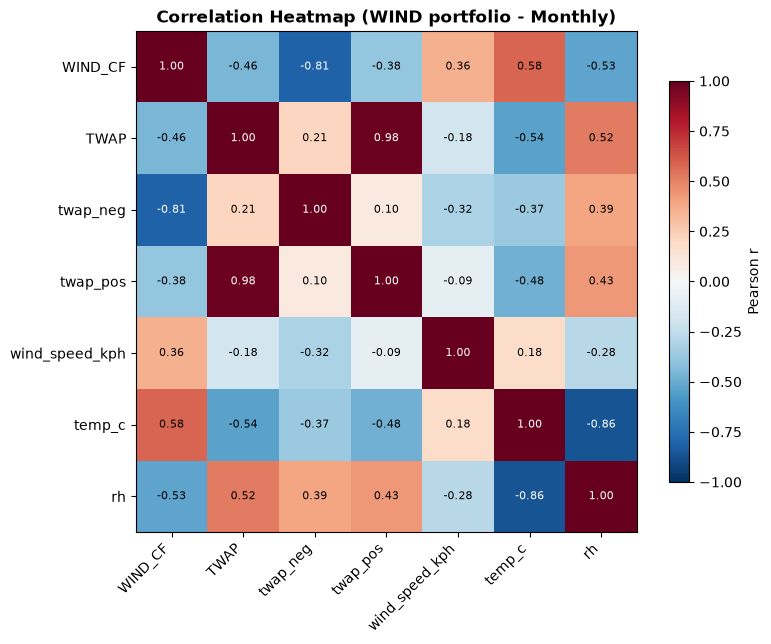

In [37]:
# =============================================================================
# CELL: EDA correlation heatmap
# Pearson correlation between the monthly WIND CF, the price features (TWAP and its
# negative/positive parts) and the main weather drivers.
# =============================================================================
eda_cols = ['target', 'twap', 'twap_neg', 'twap_pos', 'wind_speed_kph', 'temp_c', 'rh']
eda_labels = ['WIND_CF', 'TWAP', 'twap_neg', 'twap_pos', 'wind_speed_kph', 'temp_c', 'rh']

corr = df_wind[eda_cols].corr()
corr.index = eda_labels
corr.columns = eda_labels

fig, ax = plt.subplots(figsize=(8, 6.5))
im = ax.imshow(corr.values, cmap='RdBu_r', vmin=-1, vmax=1)
ax.set_xticks(range(len(eda_labels)))
ax.set_xticklabels(eda_labels, rotation=45, ha='right')
ax.set_yticks(range(len(eda_labels)))
ax.set_yticklabels(eda_labels)

# Write the correlation in each cell (white text on dark cells)
for i in range(len(eda_labels)):
    for j in range(len(eda_labels)):
        ax.text(j, i, f'{corr.values[i, j]:.2f}', ha='center', va='center', fontsize=8,
                color='white' if abs(corr.values[i, j]) > 0.6 else 'black')

fig.colorbar(im, ax=ax, shrink=0.8, label='Pearson r')
ax.set_title('Correlation Heatmap (WIND portfolio - Monthly)', fontsize=12, fontweight='bold')
plt.tight_layout()
display(fig)
plt.close(fig)

## Feature set definitions

Edit these lists to add/remove variables. Every weather-driven model uses the split price features `twap_neg` and `twap_pos` instead of the plain `twap`. Seasonal Naive and Exponential use no feature list (Exponential uses the plain monthly `twap`).

In [38]:
# =============================================================================
# CELL: Feature sets -- EDIT HERE to add/remove variables
# One feature list per weather-driven model. Price is represented by twap_neg and
# twap_pos; weather by wind_speed_kph (mean of the driver stations), rh, temp_c and
# wind direction sin/cos; seasonality by month_sin/month_cos.
# The Ensemble (average of RF and XGBoost) reuses the RF feature list.
# =============================================================================
FEATURES = {
    'Linear':   ['wind_speed_kph', 'twap_neg', 'twap_pos', 'month_sin', 'month_cos', 'rh'],
    'Ridge':    ['wind_speed_kph', 'twap_neg', 'twap_pos', 'month_sin', 'month_cos', 'rh',
                 'sin_wind_dir_raw', 'cos_wind_dir_raw', 'temp_c'],
    'LightGBM': ['wind_speed_kph', 'twap_neg', 'twap_pos', 'rh', 'temp_c', 'month_sin', 'month_cos',
                 'sin_wind_dir_raw', 'cos_wind_dir_raw'],
    'SARIMAX':  ['wind_speed_kph', 'twap_neg', 'twap_pos', 'temp_c', 'rh', 'month_sin', 'month_cos'],
    'RF':       ['wind_speed_kph', 'twap_neg', 'twap_pos', 'temp_c', 'rh', 'month_sin', 'month_cos'],
    'XGBoost':  ['wind_speed_kph', 'twap_neg', 'twap_pos', 'temp_c', 'rh', 'month_sin', 'month_cos'],
    'Ensemble': ['wind_speed_kph', 'twap_neg', 'twap_pos', 'temp_c', 'rh', 'month_sin', 'month_cos'],
}
for m, feats in FEATURES.items():
    print(f'{m:10s} {feats}')

Linear     ['wind_speed_kph', 'twap_neg', 'twap_pos', 'month_sin', 'month_cos', 'rh']
Ridge      ['wind_speed_kph', 'twap_neg', 'twap_pos', 'month_sin', 'month_cos', 'rh', 'sin_wind_dir_raw', 'cos_wind_dir_raw', 'temp_c']
LightGBM   ['wind_speed_kph', 'twap_neg', 'twap_pos', 'rh', 'temp_c', 'month_sin', 'month_cos', 'sin_wind_dir_raw', 'cos_wind_dir_raw']
SARIMAX    ['wind_speed_kph', 'twap_neg', 'twap_pos', 'temp_c', 'rh', 'month_sin', 'month_cos']
RF         ['wind_speed_kph', 'twap_neg', 'twap_pos', 'temp_c', 'rh', 'month_sin', 'month_cos']
XGBoost    ['wind_speed_kph', 'twap_neg', 'twap_pos', 'temp_c', 'rh', 'month_sin', 'month_cos']
Ensemble   ['wind_speed_kph', 'twap_neg', 'twap_pos', 'temp_c', 'rh', 'month_sin', 'month_cos']


In [39]:
# =============================================================================
# CELL: VIF (multicollinearity check)
# Variance inflation factor of the Linear model features on the training years only.
# twap_neg and twap_pos are both derived from the same price series, so watch them.
# =============================================================================
train_vif = df_wind[df_wind['FY'].isin(TRAIN_FYS)]

X_vif = train_vif[FEATURES['Linear']].dropna().copy()
X_vif.insert(0, 'const', 1)   # intercept column required by variance_inflation_factor
vif_df = pd.DataFrame({
    'Feature': X_vif.columns,
    'VIF': [variance_inflation_factor(X_vif.values, i) for i in range(X_vif.shape[1])],
})

print('=== VIF -- Linear WIND (train FY23-25) ===')
print('Rule of thumb: VIF > 5 -> moderate multicollinearity, VIF > 10 -> severe')
display(vif_df.round(2))

=== VIF -- Linear WIND (train FY23-25) ===
Rule of thumb: VIF > 5 -> moderate multicollinearity, VIF > 10 -> severe


,Feature,VIF
0,const,642.69
1,wind_speed_kph,1.54
2,twap_neg,2.92
3,twap_pos,1.41
4,month_sin,1.84
5,month_cos,4.56
6,rh,3.44


## Models

Seasonal Naive and Exponential are baselines. Linear, Ridge, LightGBM, SARIMAX, RF and XGBoost use the feature lists above (split TWAP). The Ensemble averages RF and XGBoost.

In [40]:
# =============================================================================
# CELL: Model hyperparameters
# The model functions (utilsModels) read their settings from `cfg`; edit them in
# the config cell. This cell only prints the values in use.
# =============================================================================
print('rf_params:', cfg['rf_params'])
print('xgb_params:', cfg['xgb_params'])
print('lgbm_params:', cfg['lgbm_params'])
print('alpha_grid:', cfg['alpha_grid'].round(2))
print('sarimax_order:', cfg['sarimax_order'])

rf_params: {'n_estimators': 300, 'max_depth': 4, 'min_samples_leaf': 2, 'random_state': 42}
xgb_params: {'n_estimators': 250, 'max_depth': 3, 'learning_rate': 0.05, 'subsample': 0.9, 'colsample_bytree': 0.9, 'reg_lambda': 1.0, 'random_state': 42}
lgbm_params: {'n_estimators': 200, 'max_depth': 3, 'learning_rate': 0.05, 'min_child_samples': 3, 'random_state': 42, 'verbose': -1}
alpha_grid: [  1.     1.39   1.93   2.68   3.73   5.18   7.2   10.    13.89  19.31
  26.83  37.28  51.79  71.97 100.  ]
sarimax_order: (1, 0, 0)


In [41]:
# =============================================================================
# CELL: Run all models
# Fits every model on the training years and scores it on the test year(s).
# Outputs: `results_df` (one metrics row per method) and `fitted` (predictions,
# fitted objects and features per method, reused by the plots and scenarios).
# =============================================================================
rows, fitted = run_all_models(df_wind, cfg, FEATURES, target_col='target')

results_df = pd.DataFrame(rows).round(4)
print('Done. results_df shape:', results_df.shape)

Done. results_df shape: (9, 6)


In [42]:
# =============================================================================
# CELL: Test-set report
# Metrics (MAE, RMSE, MAPE, R2) of every method on the test months, best MAE first.
# =============================================================================
print('=' * 78)
print('  WIND Contract Factor -- test set (FY2026, all 12 months)')
print('=' * 78)
display(results_df.sort_values('MAE').reset_index(drop=True))

  WIND Contract Factor -- test set (FY2026, all 12 months)


,method,n,MAE,RMSE,MAPE,R2
0,Ensemble,12,0.0822,0.0974,14.0106,0.5526
1,RF,12,0.0876,0.1004,13.6086,0.5250
2,XGBoost,12,0.0957,0.1234,17.0300,0.2822
3,LightGBM,12,0.1023,0.1238,17.2024,0.2774
4,SARIMAX,12,0.1136,0.1280,18.5571,0.2279
5,Ridge,12,0.1305,0.1496,22.5847,-0.0560
6,Linear,12,0.1358,0.1556,21.4144,-0.1415
7,Seasonal Naive,12,0.2117,0.2809,35.3027,-2.7218
8,Exponential,12,0.2845,0.3299,44.6187,-4.1319


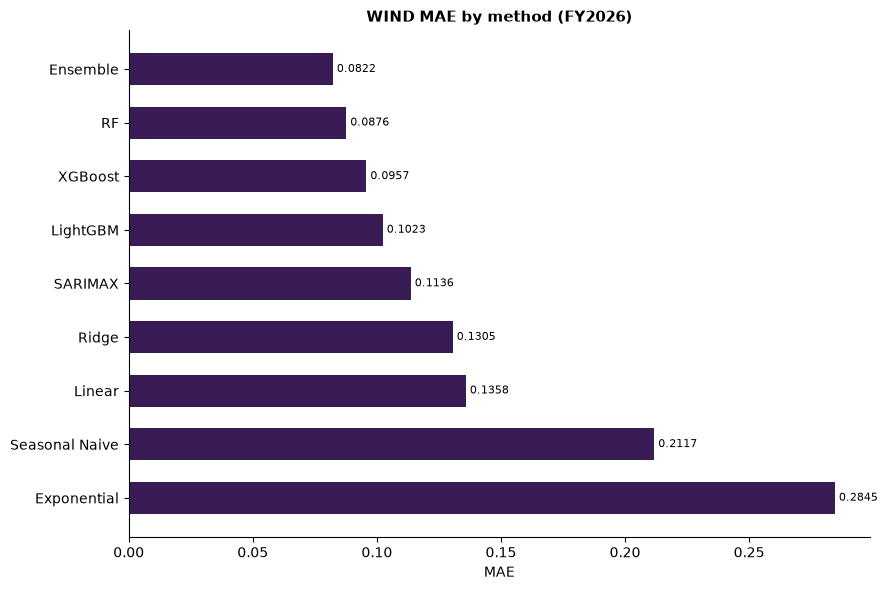

In [43]:
# =============================================================================
# CELL: MAE bar chart
# MAE of every method on the test months; the best method is at the top.
# =============================================================================
mae_sorted = results_df.sort_values('MAE')

fig, ax = plt.subplots(figsize=(9, 6))
bars = ax.barh(mae_sorted['method'], mae_sorted['MAE'], color='#391B56', height=0.6)
ax.bar_label(bars, fmt='%.4f', padding=3, fontsize=8)
ax.set_xlabel('MAE')
ax.set_title('WIND MAE by method (FY2026)', fontsize=11, fontweight='bold')
ax.invert_yaxis()                      # smallest MAE on top
ax.spines[['top', 'right']].set_visible(False)
plt.tight_layout()
display(fig)
plt.close(fig)

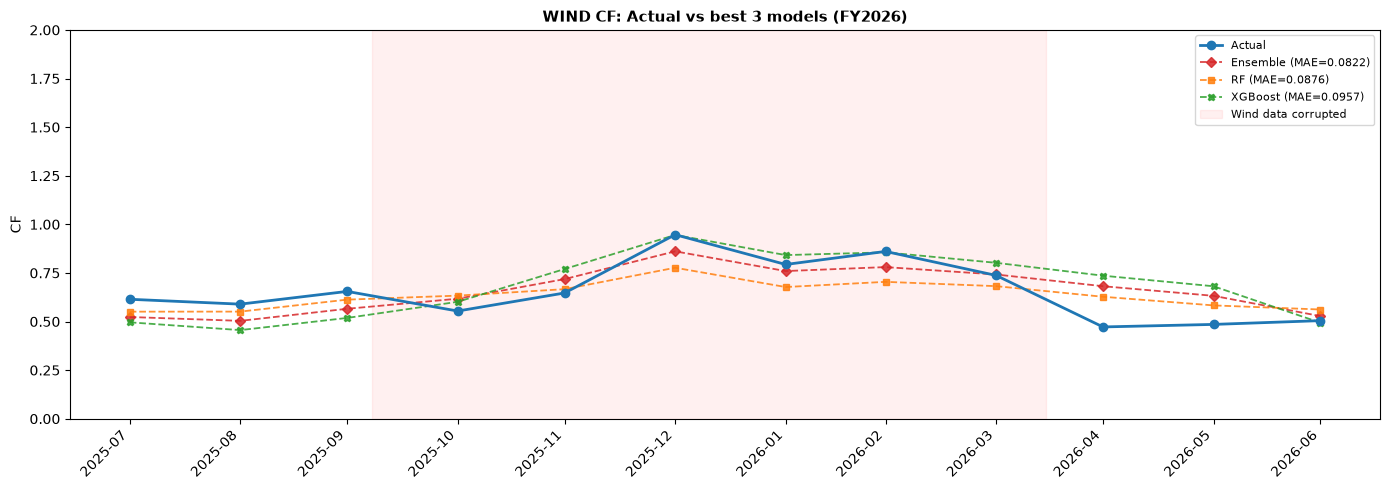

In [44]:
# =============================================================================
# CELL: Actual vs best 3 models
# Test-year CF of the three methods with the lowest MAE against the actual CF.
# The red band marks the period with corrupted wind speed data.
# =============================================================================
best3 = results_df.sort_values('MAE').head(3)
actual = df_wind.loc[df_wind['FY'].isin(TEST_FYS), 'target']

fig, ax = plt.subplots(figsize=(14, 5))
ax.plot(actual.index, actual, 'o-', color='C0', markersize=6, linewidth=2, label='Actual', zorder=5)
for i, (method, mae) in enumerate(zip(best3['method'], best3['MAE'])):
    pred = fitted[method]['pred']
    ax.plot(pred.index, pred, marker='DsX'[i], linestyle='--', color=['C3', 'C1', 'C2'][i],
            markersize=5, linewidth=1.3, alpha=0.85, label=f'{method} (MAE={mae:.4f})')

ax.axvspan(CORR_START, CORR_END, color='red', alpha=0.06, label='Wind data corrupted')
ax.set_title('WIND CF: Actual vs best 3 models (FY2026)', fontsize=11, fontweight='bold')
ax.set_ylabel('CF')
ax.set_ylim(0, 2)
ax.set_xticks(actual.index)            # one tick per month, labelled with its own month
ax.set_xticklabels([d.strftime('%Y-%m') for d in actual.index], rotation=45, ha='right')
ax.legend(fontsize=8, loc='upper right')
plt.tight_layout()
display(fig)
plt.close(fig)

In [45]:
# =============================================================================
# CELL: Feature importance (calculation)
# Linear (coef x feature std), Ridge (standardised coef) and SARIMAX (exog coef) are
# SIGNED: a negative value means a negative relationship with CF.
# RF / XGBoost / LightGBM use feature_importances_ (non-negative, scaled to sum to 1).
# Ensemble = mean of the RF and XGBoost importances.
# Result: importance[model] = {'imp': Series or None, 'signed': bool}
# =============================================================================
IMP_MODELS = ['Linear', 'Ridge', 'LightGBM', 'SARIMAX', 'RF', 'XGBoost', 'Ensemble']
train_imp = df_wind[df_wind['FY'].isin(TRAIN_FYS)]

importance = {}
for name in IMP_MODELS:
    feats, mdl = fitted[name]['feats'], fitted[name]['model']
    imp, signed = None, False
    if name == 'Linear' and mdl is not None:
        imp = pd.Series(mdl.coef_ * train_imp[feats].std().values, index=feats)
        signed = True
    elif name == 'Ridge' and mdl is not None:
        imp = pd.Series(mdl.coef_, index=feats)
        signed = True
    elif name in ('LightGBM', 'RF', 'XGBoost') and mdl is not None:
        imp = pd.Series(mdl.feature_importances_, index=feats)
    elif name == 'SARIMAX' and mdl is not None:
        imp = mdl.params.reindex(feats).dropna()
        signed = True
    elif name == 'Ensemble':
        rf_imp, xgb_imp = importance['RF']['imp'], importance['XGBoost']['imp']
        if rf_imp is not None and xgb_imp is not None:
            imp = (rf_imp.reindex(feats).fillna(0) + xgb_imp.reindex(feats).fillna(0)) / 2
    if imp is not None and not signed and imp.sum() > 0:
        imp = imp / imp.sum()
    importance[name] = {'imp': imp, 'signed': signed}

print('Feature importance computed for:', ', '.join(IMP_MODELS))
print('Linear/Ridge/SARIMAX are SIGNED; the other models are non-negative shares.')

Feature importance computed for: Linear, Ridge, LightGBM, SARIMAX, RF, XGBoost, Ensemble
Linear/Ridge/SARIMAX are SIGNED; the other models are non-negative shares.


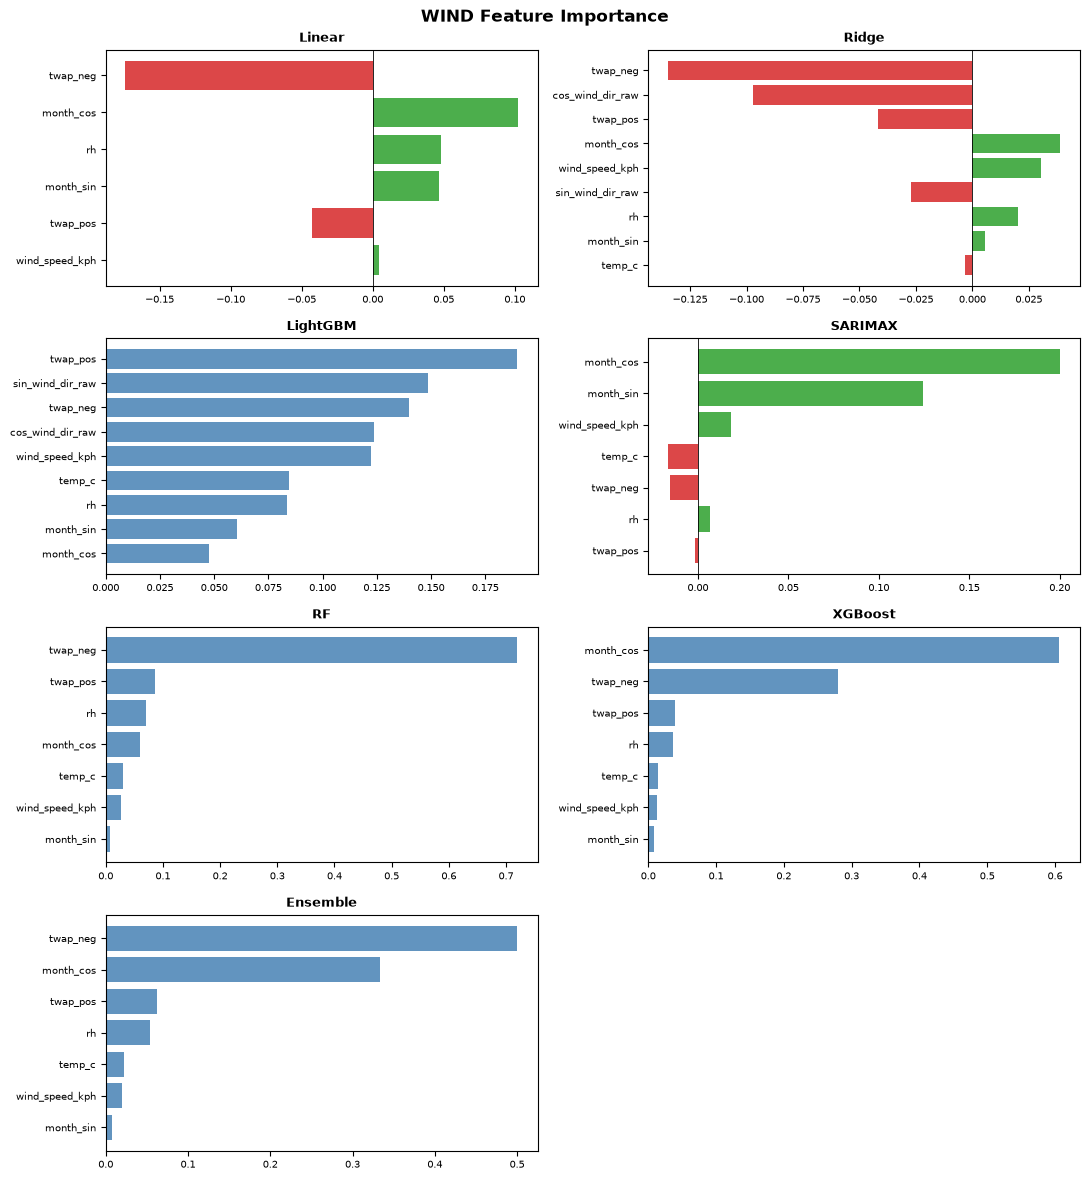

In [46]:
# =============================================================================
# CELL: Feature importance (plots)
# One bar panel per model. Signed models: green = positive effect, red = negative.
# Tree models are always >= 0 and drawn in blue.
# =============================================================================
n_cols = 2
n_rows = int(np.ceil(len(IMP_MODELS) / n_cols))
fig, axes = plt.subplots(n_rows, n_cols, figsize=(11, 3 * n_rows))
axes = axes.ravel()

for ax, name in zip(axes, IMP_MODELS):
    entry = importance[name]
    imp = entry['imp']
    if imp is None or imp.empty:
        ax.text(0.5, 0.5, 'n/a', ha='center', va='center', transform=ax.transAxes)
    else:
        imp = imp.reindex(imp.abs().sort_values().index)   # largest bar on top
        colors = ['#2ca02c' if v >= 0 else '#d62728' for v in imp.values] if entry['signed'] else 'steelblue'
        ax.barh(imp.index, imp.values, color=colors, alpha=0.85)
        ax.axvline(0, color='black', linewidth=0.6)
    ax.set_title(name, fontsize=9, fontweight='bold')
    ax.tick_params(labelsize=7)
for ax in axes[len(IMP_MODELS):]:
    ax.axis('off')                                         # hide unused panels

plt.suptitle('WIND Feature Importance', fontsize=12, fontweight='bold')
plt.tight_layout()
display(fig)
plt.close(fig)

## LGC-based negative-price adjustment for CF scenarios

Scenarios reuse historical half-hourly price structure (FY23-25). Back then negative prices were deeper because the LGC was still expensive: renewables bid down to roughly -LGC, since each MWh still earns one certificate. The LGC has dropped sharply and is expected to approach zero by the end of the LRET (2030), so future negative prices will be shallower.

Without an adjustment, the benefit of the zero-dollar floor on CF is overstated and the forecast CF comes out too high.

**Run the cells below in order. The validation cell decides whether the adjustment is warranted.**

LGC series: 2021-01-01 to 2026-09-01 (69 months)
LGC range: $2.28 - $65.61
Latest LGC: $7.88 (Sep 2026)


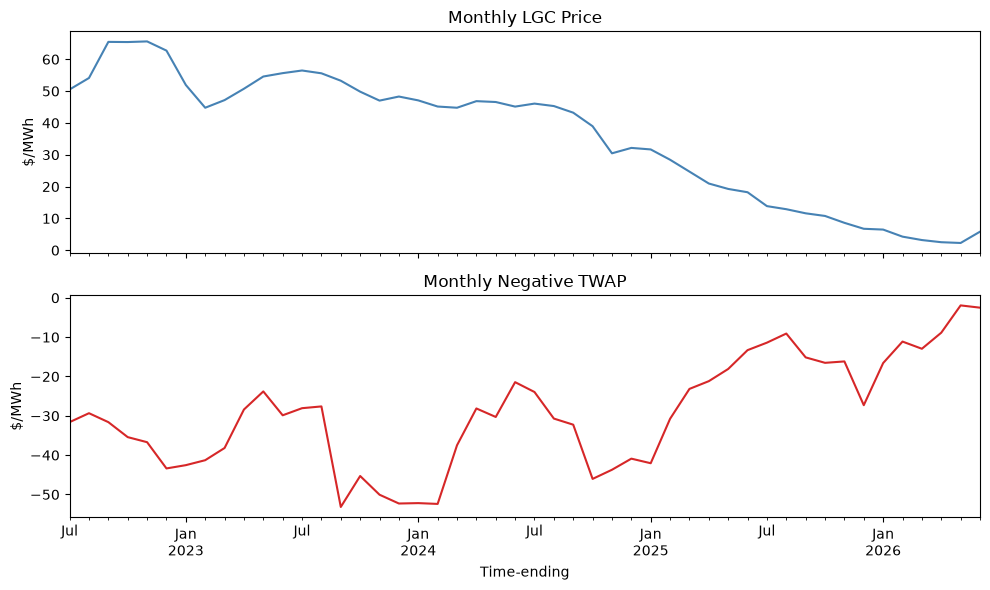

In [47]:
# =============================================================================
# CELL: Monthly LGC series and settings
# Builds the monthly LGC price `lgc_m` from the LGC file loaded above and sets the
# adjustment settings (MODE, DEPTH_Q, MIN_R). Plots LGC next to the monthly twap_neg.
# =============================================================================
lgc_m = lgc_prices['LGC'].resample('MS').mean().rename('lgc')   # snap to month start

MODE = 'empirical'      # 'empirical' (recommended) or 'lgc_ratio'
DEPTH_Q = 0.05          # quantile of half-hourly prices used as the negative-price depth
MIN_R = 0.5             # minimum within-season correlation (depth vs LGC) to justify the adjustment

# FY2023-FY2026 = Jul 2022 to Jun 2026
DATE_START = '2022-07-01'
DATE_END = '2026-06-30'
twap_neg_monthly = df_wind['twap_neg'].dropna().loc[DATE_START:DATE_END]

print(f'LGC series: {lgc_m.index.min().date()} to {lgc_m.index.max().date()} ({len(lgc_m)} months)')
print(f'LGC range: ${lgc_m.min():.2f} - ${lgc_m.max():.2f}')
print(f'Latest LGC: ${lgc_m.iloc[-1]:.2f} ({lgc_m.index[-1].strftime("%b %Y")})')

fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(10, 6), sharex=True)
lgc_m.plot(ax=ax1, title='Monthly LGC Price', ylabel='$/MWh', color='steelblue')
twap_neg_monthly.plot(ax=ax2, title='Monthly Negative TWAP', ylabel='$/MWh', color='#d62728')
plt.tight_layout()
display(fig)
plt.close(fig)

r raw = 0.507 | r within-season = 0.616
depth = 19.31 + 0.514 x LGC  (season-controlled)
Non-LGC floor: $19.3/MWh


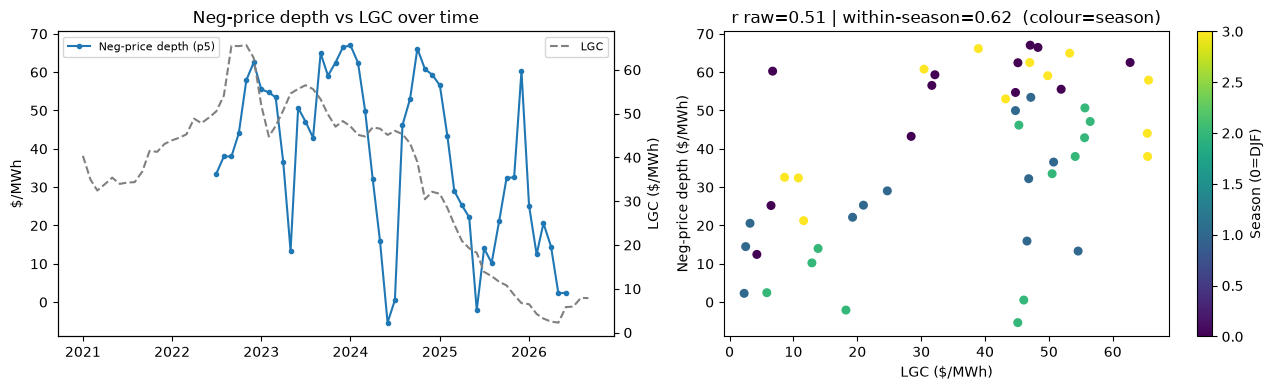

Within-season r=0.62 >= 0.5: adjustment is justified.


In [48]:
# =============================================================================
# CELL: Validate the LGC link
# Does the LGC explain the depth of negative prices? Seasonality must be controlled:
# the LGC trends down over time and negatives are deeper in spring, so the raw
# correlation is spurious. Fits depth = a + b*LGC + sin/cos(month); `a` is the
# non-LGC floor (thermal min-gen, PPA bidding) and `b` the LGC pass-through.
# Sets `a_lgc`, `b_lgc` for the shrink factor.
# =============================================================================
depth_m = (-price_hh.resample('MS').quantile(DEPTH_Q)).rename('depth')
d_lgc = pd.concat([depth_m, lgc_m], axis=1).dropna()
d_lgc = d_lgc[d_lgc.index <= price_hh.index.max()]

month_num = d_lgc.index.month
season = month_num % 12 // 3                      # 0=DJF, 1=MAM, 2=JJA, 3=SON
r_raw = d_lgc['depth'].corr(d_lgc['lgc'])
r_within = d_lgc.groupby(season).apply(lambda g: g['depth'].corr(g['lgc'])).mean()

X_reg = np.column_stack([np.ones(len(d_lgc)), d_lgc['lgc'],
                         np.sin(2 * np.pi * month_num / 12), np.cos(2 * np.pi * month_num / 12)])
coef, *_ = np.linalg.lstsq(X_reg, d_lgc['depth'].values, rcond=None)
a_lgc, b_lgc = coef[0], coef[1]

print(f'r raw = {r_raw:.3f} | r within-season = {r_within:.3f}')
print(f'depth = {a_lgc:.2f} + {b_lgc:.3f} x LGC  (season-controlled)')
print(f'Non-LGC floor: ${a_lgc:.1f}/MWh')

fig, axes = plt.subplots(1, 2, figsize=(13, 4))
ax_l = axes[0]
ax_r = ax_l.twinx()
ax_l.plot(d_lgc.index, d_lgc['depth'], 'o-', ms=3, label=f'Neg-price depth (p{int(DEPTH_Q * 100)})')
ax_r.plot(lgc_m.index, lgc_m, '--', color='grey', label='LGC')
ax_l.set_ylabel('$/MWh')
ax_r.set_ylabel('LGC ($/MWh)')
ax_l.set_title('Neg-price depth vs LGC over time')
ax_l.legend(loc='upper left', fontsize=8)
ax_r.legend(loc='upper right', fontsize=8)

sc = axes[1].scatter(d_lgc['lgc'], d_lgc['depth'], c=season, cmap='viridis', s=30)
axes[1].set_xlabel('LGC ($/MWh)')
axes[1].set_ylabel('Neg-price depth ($/MWh)')
axes[1].set_title(f'r raw={r_raw:.2f} | within-season={r_within:.2f}  (colour=season)')
fig.colorbar(sc, ax=axes[1], label='Season (0=DJF)')
fig.tight_layout()
display(fig)
plt.close(fig)

if abs(r_within) < MIN_R:
    print(f'WARNING: within-season r={r_within:.2f} < {MIN_R}. Adjustment NOT warranted -- note as a qualitative risk only.')
else:
    print(f'Within-season r={r_within:.2f} >= {MIN_R}: adjustment is justified.')

In [49]:
# =============================================================================
# CELL: Shrink factor
# `shrink_factor` (utilsScenario) gives the factor (0-1) by which historical negative
# prices are shrunk when a historical month is reused for a future month, based on
# the LGC price of the two months. LGC_CFG bundles the LGC settings it needs:
# the monthly LGC series, MODE and the fitted depth model (a_lgc, b_lgc).
# =============================================================================
LGC_CFG = {'lgc_m': lgc_m, 'mode': MODE, 'depth_ab': (a_lgc, b_lgc)}


# Example: Jul 2022 -> Jul 2025
m_a, m_b = pd.Timestamp('2022-07-01'), pd.Timestamp('2025-07-01')
if m_a in lgc_m.index and m_b in lgc_m.index:
    print(f'Example: Jul 2022 (LGC=${lgc_m[m_a]:.1f}) -> Jul 2025 (LGC=${lgc_m[m_b]:.1f}): '
          f'shrink={shrink_factor(m_a, m_b, **LGC_CFG):.3f}')

Example: Jul 2022 (LGC=$50.5) -> Jul 2025 (LGC=$13.9): shrink=0.584


In [50]:
# =============================================================================
# CELL: Scenario settings
# Scenario idea: for every test month, take the SAME calendar month of each training
# FY (FY23, FY24, FY25) -- its weather and price structure -- and set its TWAP to a
# target T. Models are trained on real FY23-25 data and then predict CF on these
# scenario rows. Two versions of each scenario:
#   raw     : historical negative prices kept as they were
#   lgc_adj : negative prices shrunk by the LGC factor first
# Everything is done at monthly level (no half-hourly rebuild).
# The scenario functions are in utilsScenario.
#
# T sources:  'actual'  = actual test-month TWAP (optimistic stand-in for a forecast)
#             'forward' = monthly TWAP of the forward price curve file
# =============================================================================
SCENARIO_FYS = list(TRAIN_FYS)                                  # FY23, FY24, FY25
SCENARIO_MODELS = ['Linear', 'Ridge', 'RF', 'XGBoost', 'LightGBM']
MODEL_ORDER = SCENARIO_MODELS + ['Ensemble']                    # Ensemble = mean of RF and XGBoost
T_SOURCES = ['actual', 'forward']
T_MAIN = 'actual'                                              # T used for `agg` / `mae_scen`
FINALISTS = ['RF', 'Ensemble']
TEST_MONTHS = df_wind.index[df_wind['FY'].isin(TEST_FYS)]
FORWARD_CURVE_PATH = os.path.join(DATA_DIR, 'VIC_Central_30min_PriceForecast.csv')

In [51]:
# =============================================================================
# CELL: Run the scenarios
# Builds the scenario rows for each T source, predicts CF with every model, takes the
# median over the scenario FYs for each test month and compares it with the actual CF.
# Outputs: scenario_df_all / agg_all / mae_all (all T sources) and agg / mae_scen
# (T_MAIN only, used by the plots), then text reports: MAE by T source, mean bias
# (forecast - actual) and the finalist models.
# =============================================================================
print(f'Mode: {MODE}  |  depth = {a_lgc:.2f} + {b_lgc:.3f} x LGC')
print(f'Scenario FYs: {SCENARIO_FYS}  |  T sources: {T_SOURCES}\n')

# Share of negative half-hours per month (needed to split the TWAP into neg/pos parts)
neg_share_monthly = (price_hh < 0).groupby(month_end_labels(price_hh.index)).mean()

# --- 1. Target T per test month ---
T_forward = load_forward_twap_monthly(FORWARD_CURVE_PATH)
T_by_source = {'actual': df_wind.loc[TEST_MONTHS, 'twap'],
               'forward': T_forward.reindex(TEST_MONTHS)}
assert T_by_source['forward'].notna().all(), 'forward curve does not cover all test months'

cmp_T = pd.DataFrame({'forward T': T_by_source['forward'], 'actual TWAP': T_by_source['actual']})
cmp_T['diff %'] = (cmp_T['forward T'] / cmp_T['actual TWAP'] - 1) * 100
print('=' * 70)
print('Forward T vs actual TWAP, test months')
print('=' * 70)
print(cmp_T.round(1).to_string())
print(f'\nMean |diff| = {cmp_T["diff %"].abs().mean():.1f}%  |  max = {cmp_T["diff %"].abs().max():.1f}%\n')

# --- 2. Predictions for every T source, version and model ---
frames = []
for t_source in T_SOURCES:
    scen = build_scenario_table(df_wind, neg_share_monthly, T_by_source[t_source], SCENARIO_FYS, **LGC_CFG)
    for method, pred in predict_scenarios(fitted, scen, MODEL_ORDER).items():
        tmp = scen[['_month', '_fy', '_version', '_actual', '_T']].copy()
        tmp.columns = ['month', 'scenario_fy', 'version', 'actual_cf', 'T']
        tmp['t_source'], tmp['method'], tmp['pred_cf'] = t_source, method, pred
        frames.append(tmp)
scenario_df_all = pd.concat(frames, ignore_index=True)

# --- 3. Median across scenario FYs per month, then MAE and bias vs actual ---
agg_all = scenario_df_all.groupby(['t_source', 'month', 'version', 'method']).agg(
    pred_median=('pred_cf', 'median'), actual_cf=('actual_cf', 'first')).reset_index()
agg_all['abs_error'] = (agg_all['pred_median'] - agg_all['actual_cf']).abs()
agg_all['bias'] = agg_all['pred_median'] - agg_all['actual_cf']          # > 0: forecast above actual

mae_all = agg_all.groupby(['t_source', 'method', 'version'])['abs_error'].mean().unstack('version')

# Tables for T_MAIN, used by the plotting cells
agg = agg_all[agg_all['t_source'] == T_MAIN].drop(columns='t_source').copy()
mae_scen = mae_all.loc[T_MAIN].copy()
mae_scen['delta'] = mae_scen['lgc_adj'] - mae_scen['raw']
mae_scen['improved'] = mae_scen['delta'] < 0

# --- 4. Text reports ---
tbl = pd.concat({f'T={t}': mae_all.loc[t][['raw', 'lgc_adj']] for t in T_SOURCES}, axis=1)
tbl = tbl.sort_values((f'T={T_MAIN}', 'lgc_adj'))
print('=' * 70)
print(f'Scenario MAE (median of {len(SCENARIO_FYS)} scenarios vs actual), by source of T')
print('=' * 70)
print(tbl.round(4).to_string())

print('\n' + '=' * 70)
print('Mean bias (forecast - actual), averaged over all models and test months')
print('=' * 70)
print(agg_all.groupby(['t_source', 'version'])['bias'].mean().unstack('version').round(3).to_string())

print('\n' + '=' * 70)
print('Finalists: MAE unadjusted -> LGC-adjusted')
print('=' * 70)
for m in FINALISTS:
    parts = [f'T={t}: {mae_all.loc[(t, m), "raw"]:.4f} -> {mae_all.loc[(t, m), "lgc_adj"]:.4f}'
             for t in T_SOURCES]
    print(f'{m:10s} ' + '  |  '.join(parts))

print(f'\nTotal scenario predictions: {len(scenario_df_all):,}')

Mode: empirical  |  depth = 19.31 + 0.514 x LGC
Scenario FYs: [2023, 2024, 2025]  |  T sources: ['actual', 'forward']

Forward T vs actual TWAP, test months
             forward T  actual TWAP  diff %
Time-ending                                
2025-07-31        87.6         82.1     6.7
2025-08-31        98.1         93.2     5.3
2025-09-30        73.5         55.2    33.1
2025-10-31        54.4         51.4     5.8
2025-11-30        62.0         31.8    94.7
2025-12-31        66.5         27.5   141.5
2026-01-31       108.5         38.6   181.5
2026-02-28        69.8         45.1    54.9
2026-03-31       107.4         44.7   140.2
2026-04-30        62.8         35.7    75.9
2026-05-31        41.6         64.8   -35.8
2026-06-30        93.9         66.8    40.6

Mean |diff| = 68.0%  |  max = 181.5%

Scenario MAE (median of 3 scenarios vs actual), by source of T
         T=actual         T=forward        
version       raw lgc_adj       raw lgc_adj
method                               

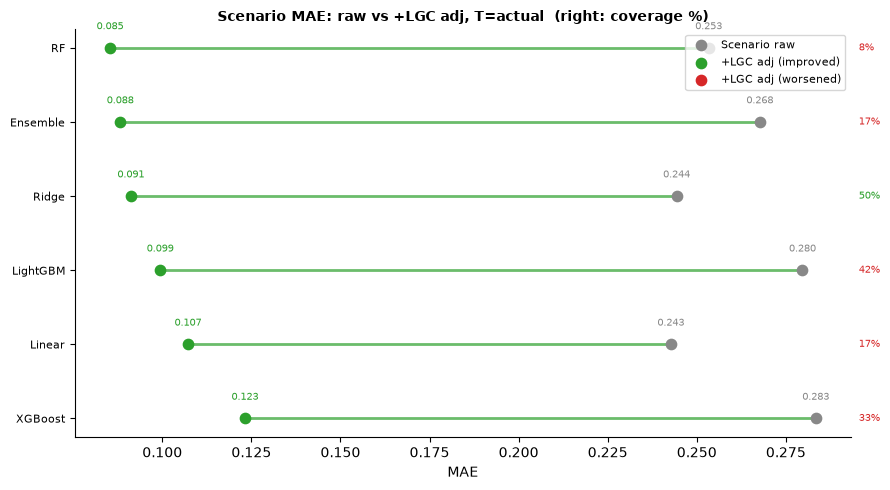

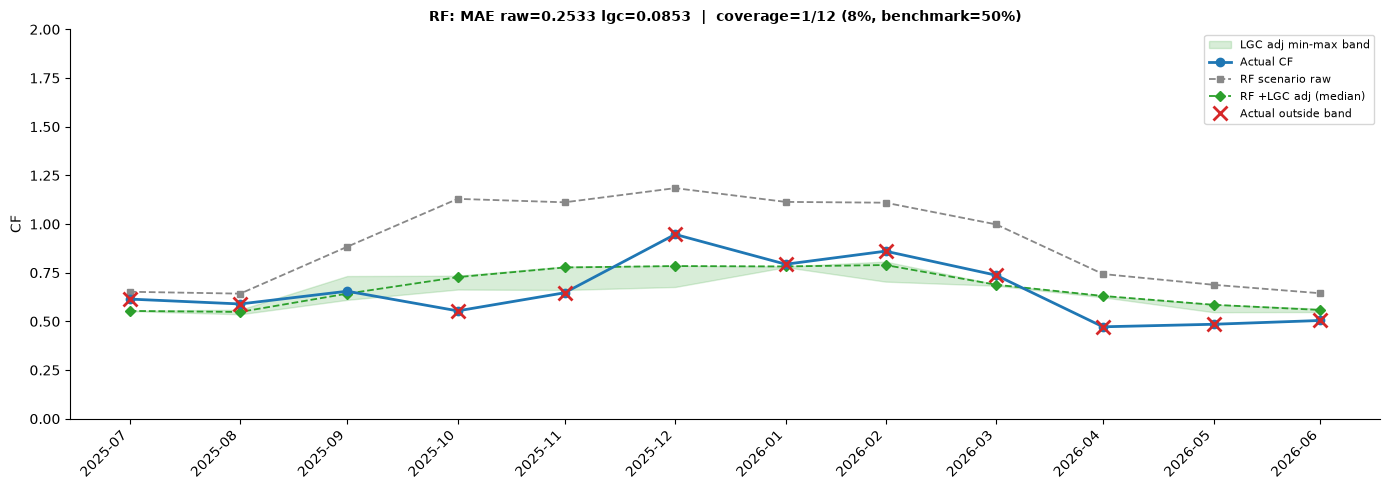


--- Direct model MAE (real test-year inputs) vs scenario MAE ---


version,direct,scen_raw,scen_lgc_adj
method,,,
Ensemble,0.0822,0.2677,0.0882
LightGBM,0.1023,0.2796,0.0994
Linear,0.1358,0.2427,0.1072
RF,0.0876,0.2533,0.0853
Ridge,0.1305,0.2443,0.0912
XGBoost,0.0957,0.2834,0.1232


--- Interval coverage (LGC adj): actual inside [min, max] of 3 scenarios; benchmark 50% ---


,coverage,mean_width,flag
method,,,
Ridge,0.500,0.128,ok
LightGBM,0.417,0.102,narrow
XGBoost,0.333,0.082,narrow
Ensemble,0.167,0.063,narrow
Linear,0.167,0.100,narrow
RF,0.083,0.052,narrow


In [52]:
# =============================================================================
# CELL: Scenario results -- dumbbell, timeline, coverage
# 1. Coverage: share of test months where the actual CF lies inside [min, max] of the
#    scenario predictions (benchmark (n-1)/(n+1) for n scenarios).
# 2. Dumbbell: scenario MAE raw vs LGC-adjusted per model (right: coverage %).
# 3. Timeline of the best model with its min-max band.
# 4. Direct-model MAE vs scenario MAE, and the coverage table.
# Uses T = T_MAIN.
# =============================================================================
n_scen = len(SCENARIO_FYS)
cov_benchmark = (n_scen - 1) / (n_scen + 1)          # 50% for 3 scenarios

cov = scenario_df_all[scenario_df_all['t_source'] == T_MAIN].groupby(['month', 'version', 'method']).agg(
    lo=('pred_cf', 'min'), hi=('pred_cf', 'max'), actual=('actual_cf', 'first')).reset_index()
cov['inside'] = cov['actual'].between(cov['lo'], cov['hi'])
cov['width'] = cov['hi'] - cov['lo']
cov_rate = cov.groupby(['version', 'method']).agg(coverage=('inside', 'mean'),
                                                   mean_width=('width', 'mean')).round(3)

# --- Dumbbell: raw vs lgc_adj MAE per model ---
sub = mae_scen.sort_values('lgc_adj').reset_index()
y_pos = np.arange(len(sub))
improved = (sub['delta'] < 0).values

fig, ax = plt.subplots(figsize=(9, 5))
for yi in y_pos:
    ax.plot([sub['raw'][yi], sub['lgc_adj'][yi]], [yi, yi],
            color='#2ca02c' if improved[yi] else '#d62728', linewidth=2, alpha=0.7, zorder=1)
ax.scatter(sub['raw'], y_pos, color='#888888', s=55, label='Scenario raw', zorder=2)
ax.scatter(sub.loc[improved, 'lgc_adj'], y_pos[improved], color='#2ca02c', s=55, label='+LGC adj (improved)', zorder=3)
ax.scatter(sub.loc[~improved, 'lgc_adj'], y_pos[~improved], color='#d62728', s=55, label='+LGC adj (worsened)', zorder=3)

for yi in y_pos:
    c = '#2ca02c' if improved[yi] else '#d62728'
    ax.text(sub['raw'][yi], yi - 0.22, f'{sub["raw"][yi]:.3f}', va='bottom', ha='center', fontsize=7, color='#888888')
    ax.text(sub['lgc_adj'][yi], yi - 0.22, f'{sub["lgc_adj"][yi]:.3f}', va='bottom', ha='center', fontsize=7, color=c)
    cov_val = cov_rate.loc[('lgc_adj', sub['method'][yi]), 'coverage']
    ax.text(1.01, yi, f'{cov_val:.0%}', va='center', ha='left', fontsize=7,
            color='#2ca02c' if cov_val >= cov_benchmark else '#d62728', transform=ax.get_yaxis_transform())

ax.set_yticks(y_pos)
ax.set_yticklabels(sub['method'], fontsize=8)
ax.invert_yaxis()
ax.set_xlabel('MAE')
ax.set_title(f'Scenario MAE: raw vs +LGC adj, T={T_MAIN}  (right: coverage %)', fontsize=10, fontweight='bold')
ax.spines[['top', 'right']].set_visible(False)
ax.legend(loc='upper right', fontsize=8)
plt.tight_layout()
display(fig)
plt.close(fig)

# --- Timeline of the best model (by LGC-adjusted MAE) with the min-max band ---
best = mae_scen['lgc_adj'].idxmin()
s_agg = agg[agg['method'] == best].set_index(['month', 'version'])
s_cov = cov[(cov['method'] == best) & (cov['version'] == 'lgc_adj')].set_index('month')
months = sorted(s_agg.index.get_level_values('month').unique())
actual_vals = np.array([s_agg.loc[(m, 'raw'), 'actual_cf'] for m in months])
pred_raw = np.array([s_agg.loc[(m, 'raw'), 'pred_median'] for m in months])
pred_adj = np.array([s_agg.loc[(m, 'lgc_adj'), 'pred_median'] for m in months])
inside = s_cov.loc[months, 'inside'].values

fig2, ax2 = plt.subplots(figsize=(14, 5))
ax2.fill_between(months, s_cov.loc[months, 'lo'], s_cov.loc[months, 'hi'], alpha=0.18, color='#2ca02c',
                 label='LGC adj min-max band')
ax2.plot(months, actual_vals, 'o-', color='C0', ms=6, lw=2, label='Actual CF', zorder=5)
ax2.plot(months, pred_raw, 's--', color='#888888', ms=5, lw=1.3, label=f'{best} scenario raw')
ax2.plot(months, pred_adj, 'D--', color='#2ca02c', ms=5, lw=1.3, label=f'{best} +LGC adj (median)')
ax2.plot(np.array(months)[~inside], actual_vals[~inside], 'x', color='#d62728', ms=10, mew=2, zorder=6,
         label='Actual outside band')
ax2.set_title(f'{best}: MAE raw={np.nanmean(np.abs(pred_raw - actual_vals)):.4f} '
              f'lgc={np.nanmean(np.abs(pred_adj - actual_vals)):.4f}  |  '
              f'coverage={inside.sum()}/{len(months)} ({inside.mean():.0%}, benchmark={cov_benchmark:.0%})',
              fontsize=10, fontweight='bold')
ax2.set_ylabel('CF')
ax2.set_ylim(0, 2.0)
ax2.set_xticks(months)
ax2.set_xticklabels([m.strftime('%Y-%m') for m in months], rotation=45, ha='right')
ax2.legend(fontsize=8, loc='upper right')
ax2.spines[['top', 'right']].set_visible(False)
plt.tight_layout()
display(fig2)
plt.close(fig2)

# --- Direct model MAE vs scenario MAE ---
direct_mae = results_df.set_index('method')['MAE']
mae_cmp = mae_scen[['raw', 'lgc_adj']].rename(columns={'raw': 'scen_raw', 'lgc_adj': 'scen_lgc_adj'})
mae_cmp.insert(0, 'direct', direct_mae.reindex(mae_cmp.index))
print('\n--- Direct model MAE (real test-year inputs) vs scenario MAE ---')
display(mae_cmp.round(4))

# --- Coverage table ---
print(f'--- Interval coverage (LGC adj): actual inside [min, max] of {n_scen} scenarios; benchmark {cov_benchmark:.0%} ---')
cov_table = cov_rate.loc['lgc_adj'].sort_values('coverage', ascending=False).copy()
cov_table['flag'] = np.where(cov_table['coverage'] >= cov_benchmark, 'ok', 'narrow')
display(cov_table)

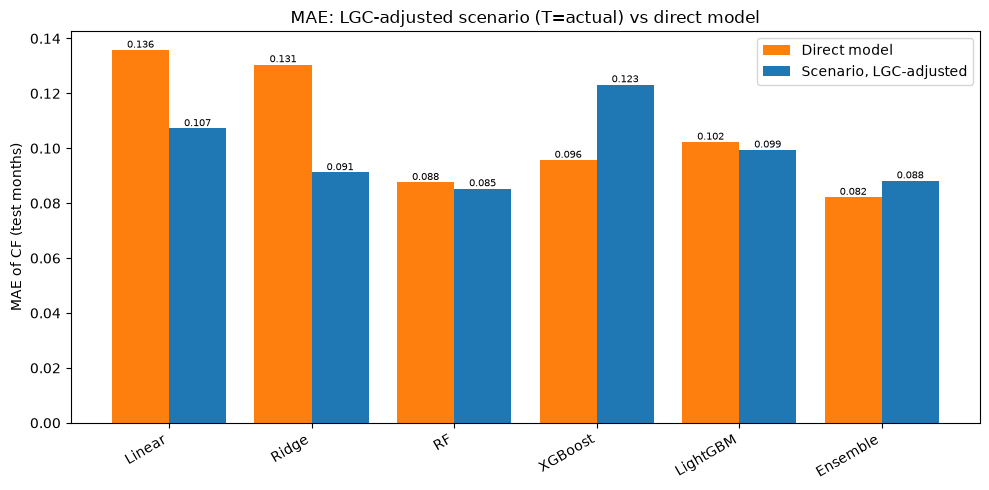

In [53]:
# =============================================================================
# CELL: Scenario MAE vs direct model (bar chart)
# Grouped bars per model: direct model (real test-year inputs, a benchmark that
# "knows" the test year) vs the LGC-adjusted scenario forecast (T = T_MAIN).
# =============================================================================
def plot_scenario_mae_bars(mae_scen, direct_mae, show_unadjusted=False):
    """Grouped bar chart of MAE per model: direct model vs scenario forecast.

    Args:
        mae_scen: Scenario MAE table (index = method, columns 'raw', 'lgc_adj').
        direct_mae: Series of direct-model MAE indexed by method.
        show_unadjusted: Also draw the unadjusted scenario as a third bar.
    """
    series = [('direct', 'Direct model', 'tab:orange'), ('lgc_adj', 'Scenario, LGC-adjusted', 'tab:blue')]
    if show_unadjusted:
        series.insert(1, ('raw', 'Scenario, unadjusted', 'lightgrey'))

    tab = mae_scen.reindex(MODEL_ORDER).copy()
    tab['direct'] = direct_mae.reindex(MODEL_ORDER)

    n = len(series)
    w = 0.8 / n
    x = np.arange(len(MODEL_ORDER))
    fig, ax = plt.subplots(figsize=(10, 5))
    for k, (col, label, color) in enumerate(series):
        bars = ax.bar(x + (k - (n - 1) / 2) * w, tab[col], w, color=color, label=label)
        ax.bar_label(bars, fmt='%.3f', fontsize=7)
    ax.set_xticks(x)
    ax.set_xticklabels(MODEL_ORDER, rotation=30, ha='right')
    ax.set_ylabel('MAE of CF (test months)')
    ax.set_title(f'MAE: LGC-adjusted scenario (T={T_MAIN}) vs direct model')
    ax.legend()
    fig.tight_layout()
    display(fig)
    plt.close(fig)


plot_scenario_mae_bars(mae_scen, results_df.set_index('method')['MAE'])

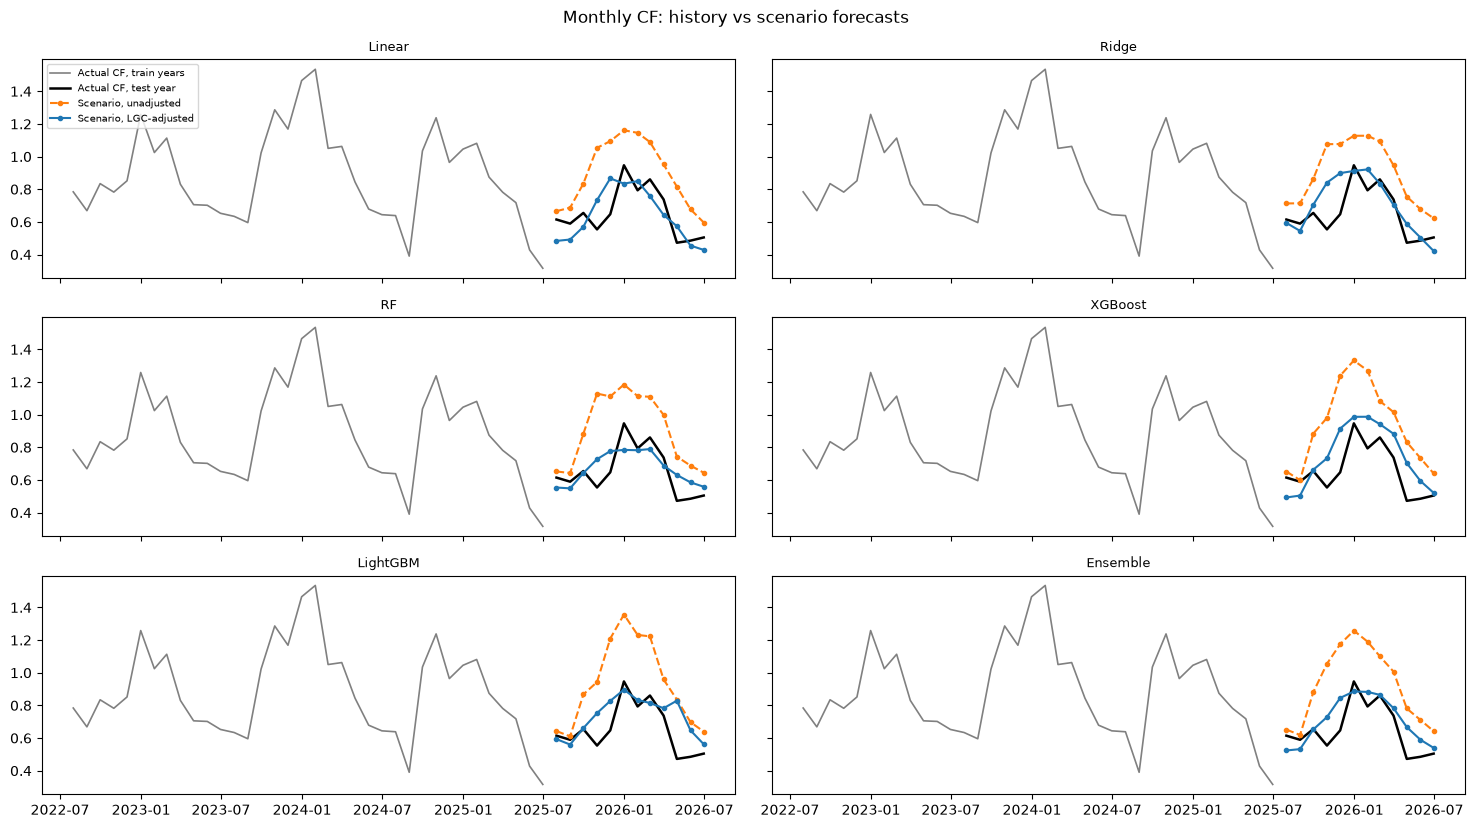

In [54]:
# =============================================================================
# CELL: Monthly CF time series
# One panel per model: training-year CF, actual test-year CF, and the unadjusted /
# LGC-adjusted scenario forecasts (median over scenarios, T = T_MAIN).
# =============================================================================
def plot_cf_timeseries(agg, df_src, models=MODEL_ORDER, n_cols=2):
    """Plot monthly CF history and the scenario forecasts, one panel per model.

    Args:
        agg: Monthly median scenario forecasts (columns month, version, method,
            pred_median, actual_cf).
        df_src: Monthly feature table with 'FY' and 'target'.
    """
    hist = df_src.loc[df_src['FY'].isin(TRAIN_FYS), 'target']       # context: training-year CF
    n_rows = int(np.ceil(len(models) / n_cols))
    fig, axes = plt.subplots(n_rows, n_cols, figsize=(15, 2.8 * n_rows), sharex=True, sharey=True)
    axes = np.atleast_1d(axes).ravel()

    for ax, name in zip(axes, models):
        sub = agg[agg['method'] == name]
        raw = sub[sub['version'] == 'raw'].set_index('month').sort_index()
        adj = sub[sub['version'] == 'lgc_adj'].set_index('month').sort_index()
        if raw.empty:
            ax.set_title(f'{name} (no data)', fontsize=9)
            continue
        ax.plot(hist.index, hist.values, color='grey', lw=1.2, label='Actual CF, train years')
        ax.plot(raw.index, raw['actual_cf'], color='black', lw=1.8, label='Actual CF, test year')
        ax.plot(raw.index, raw['pred_median'], color='tab:orange', ls='--', marker='o', ms=3,
                label='Scenario, unadjusted')
        ax.plot(adj.index, adj['pred_median'], color='tab:blue', marker='o', ms=3,
                label='Scenario, LGC-adjusted')
        ax.set_title(name, fontsize=9)
    for ax in axes[len(models):]:
        ax.axis('off')

    axes[0].legend(fontsize=7, loc='upper left')
    fig.suptitle('Monthly CF: history vs scenario forecasts')
    fig.tight_layout()
    display(fig)
    plt.close(fig)


plot_cf_timeseries(agg, df_wind)

In [55]:
# =============================================================================
# CELL: Sensitivity to the depth definition
# How much does the definition of "negative-price depth" matter? For each definition
# (P1, P5, P10 of the monthly half-hourly prices, or the mean of the negatives) refit
# depth = a + b*LGC + season terms, rerun the LGC-adjusted scenarios with that (a, b)
# and compare the MAE. Uses T = actual TWAP so it is comparable with `mae_all`.
# =============================================================================
DEPTH_SPECS = {'P1': 0.01, 'P5 (current)': 0.05, 'P10': 0.10, 'mean of negatives': 'neg_mean'}


def fmt4(x):
    """Format a float with 4 decimals (for to_string)."""
    return f'{x:.4f}'


def fit_depth_model(how):
    """Fit depth = a + b*LGC + c1*sin + c2*cos; return coefficients and fit diagnostics."""
    d_q = pd.concat([monthly_depth(price_hh, how), lgc_m], axis=1).dropna()
    d_q = d_q[d_q.index <= price_hh.index.max()]
    m = d_q.index.month
    X = np.column_stack([np.ones(len(d_q)), d_q['lgc'], np.sin(2 * np.pi * m / 12), np.cos(2 * np.pi * m / 12)])
    coef, *_ = np.linalg.lstsq(X, d_q['depth'].values, rcond=None)
    a_q, b_q = coef[0], coef[1]
    r_within = d_q.groupby(m % 12 // 3).apply(lambda g: g['depth'].corr(g['lgc'])).mean()
    return {'a': a_q, 'b': b_q, 'a/b': a_q / b_q if b_q != 0 else np.nan,
            'r_raw': d_q['depth'].corr(d_q['lgc']), 'r_within': r_within,
            'months': len(d_q), 'months depth<0': int((d_q['depth'] < 0).sum())}


def lgc_adj_mae(a_val, b_val):
    """Scenario MAE per model (LGC-adjusted version, T = actual TWAP) for a given depth model (a, b)."""
    scen = build_scenario_table(df_wind, neg_share_monthly, T_by_source['actual'], SCENARIO_FYS,
                                **dict(LGC_CFG, depth_ab=(a_val, b_val)), versions=(('lgc_adj', True),))
    frames = [pd.DataFrame({'month': scen['_month'], 'method': m, 'pred': p, 'actual': scen['_actual']})
              for m, p in predict_scenarios(fitted, scen, MODEL_ORDER).items()]
    med = pd.concat(frames).groupby(['month', 'method']).agg(pred=('pred', 'median'),
                                                              actual=('actual', 'first')).reset_index()
    med['abs_err'] = (med['pred'] - med['actual']).abs()
    return med.groupby('method')['abs_err'].mean()


# --- Part 1: depth model for each definition ---
fits, mae_by_spec = {}, {}
for label, how in DEPTH_SPECS.items():
    fits[label] = fit_depth_model(how)
    if fits[label]['b'] > 0:                      # a non-positive slope would switch the shrink off
        mae_by_spec[label] = lgc_adj_mae(fits[label]['a'], fits[label]['b'])
    else:
        print(f'{label}: b <= 0, no adjustment possible')

fit_df = pd.DataFrame(fits).T
fit_df[['months', 'months depth<0']] = fit_df[['months', 'months depth<0']].astype(int)
print('=' * 90)
print('Depth model by definition (depth = a + b*LGC + season terms)')
print('=' * 90)
print(fit_df.to_string(float_format=lambda x: f'{x:.3f}'))

# --- Part 2: scenario MAE by depth definition ---
tab = pd.DataFrame({'unadjusted': mae_all.loc['actual']['raw'], **mae_by_spec})
tab['range across definitions'] = tab[list(mae_by_spec)].max(axis=1) - tab[list(mae_by_spec)].min(axis=1)
print('\n' + '=' * 90)
print('LGC-adjusted scenario MAE by depth definition (T = actual)')
print('=' * 90)
print(tab.sort_values('P5 (current)').to_string(float_format=fmt4))

print('\nKey models (finalists):')
for m in FINALISTS:
    vals = {lab: mae[m] for lab, mae in mae_by_spec.items()}
    print(f'  {m:10s} ' + '  '.join(f'{lab}={v:.4f}' for lab, v in vals.items())
          + f'  | range={max(vals.values()) - min(vals.values()):.4f}')

Depth model by definition (depth = a + b*LGC + season terms)
                       a     b    a/b  r_raw  r_within  months  months depth<0
P1                47.687 0.604 78.985  0.319     0.521      48               0
P5 (current)      19.311 0.514 37.602  0.507     0.616      48               2
P10               11.870 0.378 31.417  0.380     0.476      48               6
mean of negatives 11.891 0.485 24.520  0.703     0.831      48               0

LGC-adjusted scenario MAE by depth definition (T = actual)
          unadjusted     P1  P5 (current)    P10  mean of negatives  range across definitions
method                                                                                       
RF            0.2533 0.1140        0.0853 0.0926             0.0923                    0.0287
Ensemble      0.2677 0.1256        0.0882 0.0905             0.0951                    0.0374
Ridge         0.2443 0.1176        0.0912 0.0901             0.0902                    0.0275
LightGBM      

In [56]:
# =============================================================================
# CELL: Sensitivity to T
# CF = DWAP / TWAP, so why does the forecast barely move when T is far off? Here
# T = actual TWAP x a multiplier (0.5 ... 2.0); the LGC-adjusted scenarios are rebuilt
# and the forecast recomputed. Only twap_pos follows T (twap_neg stays at its adjusted
# level), so the model reacts to T only through twap_pos.
# =============================================================================
T_MULTS = [0.5, 0.75, 1.0, 1.25, 1.5, 2.0]
SENS_METHODS = ['RF', 'Ensemble', 'Linear']


results = []
for mult in T_MULTS:
    scen = build_scenario_table(df_wind, neg_share_monthly, T_by_source['actual'] * mult, SCENARIO_FYS,
                                **LGC_CFG, versions=(('lgc_adj', True),))
    for method in SENS_METHODS:
        mean_pred, mae, mean_actual = summarise(scen, predict_method(fitted, method, scen))
        results.append({'method': method, 't_mult': mult, 'mean_pred': mean_pred,
                        'mae': mae, 'mean_actual': mean_actual})
res = pd.DataFrame(results)

print('=' * 70)
print(f'Mean forecast CF vs T multiplier (actual mean CF = {res["mean_actual"].iloc[0]:.3f})')
print('=' * 70)
print(res.pivot(index='method', columns='t_mult', values='mean_pred').round(3).to_string())
print('\nMAE vs T multiplier')
print(res.pivot(index='method', columns='t_mult', values='mae').round(4).to_string())

Mean forecast CF vs T multiplier (actual mean CF = 0.655)
t_mult     0.50   0.75   1.00   1.25   1.50   2.00
method                                            
Ensemble  0.743  0.726  0.708  0.678  0.663  0.631
Linear    0.663  0.652  0.641  0.629  0.618  0.597
RF        0.679  0.675  0.672  0.662  0.656  0.641

MAE vs T multiplier
t_mult      0.50    0.75    1.00    1.25    1.50    2.00
method                                                  
Ensemble  0.1008  0.0960  0.0882  0.0799  0.0834  0.0874
Linear    0.0965  0.1019  0.1072  0.1126  0.1176  0.1276
RF        0.0848  0.0850  0.0853  0.0894  0.0923  0.0913
